# Getting started with `error_discovery`

What the model is, what error is injected into it, and how to drive the package.

Everything here calls into the modules; nothing is reimplemented. For the index of what
exists, see `error_discovery/README.md`.

**This notebook writes nothing.** It runs no study, regenerates no figure, and leaves
`results/` untouched — the two figures near the end are the committed ones, displayed from
disk. Re-run it as often as you like. Top to bottom it takes about half a minute, almost all
of it one 3-year integration in §1.

## 0. Setup, and the index of what exists

The package is installed editable, so `error_discovery`, `qgs_jax` and `qgs` import from any
working directory — no `PYTHONPATH`, no `sys.path` surgery. Use the `dqgs` conda env; the
base env has no numpy.

In [1]:
import os, sys, subprocess
import numpy as np
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
from IPython.display import Image, display

from error_discovery import config, formfit, discovery
from error_discovery.models import obs_mask
from error_discovery.attractor import get_attractor_ic
from qgs_jax import model as jm
import qgs

print("python  :", sys.executable)
print("jax     :", jax.__version__)
print("float64 :", jnp.zeros(1).dtype)   # qgs_jax enables x64 on import; nothing here is f32
print("qgs     :", qgs.__version__, " <- stale string upstream ships at the 1.0.0 tag; trust the pin")
print("results :", config.RESULTS_DIR)

python  : /Users/aipa1027/miniconda3/envs/dqgs/bin/python
jax     : 0.10.1
float64 : float64
qgs     : 0.2.8  <- stale string upstream ships at the 1.0.0 tag; trust the pin
results : /Users/aipa1027/Library/CloudStorage/OneDrive-UCB-O365/Documents/research/da_climate_model_improvements/dqgs_project/dqgs/error_discovery/results


Each study is one entry in `run_all.STUDIES`. The command-line flags are *generated* from
that table, so the list below and `python -m error_discovery.run_all --help` cannot drift
apart. §4 comes back to how you drive them.

In [2]:
from error_discovery.run_all import STUDIES, DEFAULT

for name, s in STUDIES.items():
    flag = "(default)" if name == DEFAULT else f"--{name}"
    print(f"{flag:17s} {s.help}")
print(f"\n{len(STUDIES)} studies. One runs per invocation.")

(default)         lead-time window of discoverability (the default study)
--sparsity        partial-observation study (which variables are observed)
--form            form discovery from trajectories (E1-E5)
--obstruction     near-constant-mode identifiability obstruction + eps-scaling
--reanalysis      is reanalysis far enough to identify the error form?
--increment       do DA increments unlock discovery?
--why             why only off-attractor data identifies the form (governing law, global-form control, Lyapunov provenance)
--robustness      robustness of the mean/std diagnostic (approximate law + parsimony floor)
--overcomplete    the over-complete library succeeds off the attractor (boundary complement)
--donoharm        does an L1/sparsity penalty rescue the attractor? (no, under model-form error)
--climatology     climatology fidelity of the recovered correction (the error is climatologically silent)
--driver-scan     which driver is discoverable on the attractor: margin vs th

## 1. The model

MAOOAM: a coupled ocean–atmosphere model reduced by Galerkin projection to **36 spectral
amplitudes**. `variables_range` splits the state into four blocks. Three modes carry the
argument later — the leading atmospheric streamfunction, the leading atmospheric temperature,
and the leading ocean temperature, which is the slow one.

In [3]:
tw = formfit.twin()                 # the canonical twin: injected error driven by g = T_o1
cfg = config.ExperimentConfig()
vr = tw.spec.variables_range

print(f"ndim = {tw.ndim}    variables_range = {vr}")
print(f"  psi_a   x[0:{vr[0]}]"
      f"    theta_a x[{vr[0]}:{vr[1]}]"
      f"    psi_o x[{vr[1]}:{vr[2]}]"
      f"    T_o   x[{vr[2]}:{vr[3]}]")
print(f"\nload-bearing modes:  psi_a1 = x[{tw.idx_psia1}]"
      f"   theta_a1 = x[{tw.idx_thetaa1}]   T_o1 = x[{tw.idx_To1}]")
print(f"\ntime: dt = {config.DT} nondim = {1/config.STEPS_PER_DAY:.4f} days"
      f"   ({config.STEPS_PER_DAY:.2f} steps/day)")

ndim = 36    variables_range = (10, 20, 28, 36)
  psi_a   x[0:10]    theta_a x[10:20]    psi_o x[20:28]    T_o   x[28:36]

load-bearing modes:  psi_a1 = x[0]   theta_a1 = x[10]   T_o1 = x[28]

time: dt = 0.1 nondim = 0.0112 days   (89.16 steps/day)


### The whole model is one sparse quadratic form

After projection the dynamics are exactly quadratic. The entire vector field is a single
rank-3 tensor contracted against the state twice:

```
f(x)_i = sum_jk T[i,j,k] * xbar_j * xbar_k        with  xbar = (1, x)
```

That is the *only* thing `qgs_jax.model.tendencies` does. Two consequences worth seeing
directly: the tensor is almost entirely zeros, and the Jacobian has a closed form — so the
tangent-linear and adjoint models come for free, with no hand-coding and no finite
differences.

In [4]:
T = np.asarray(tw.T_base)
print(f"tendency tensor : {T.shape}   nonzero {100*(T != 0).mean():.2f}%"
      f"   ({int((T != 0).sum())} of {T.size} entries)")

x0 = jnp.asarray(np.random.default_rng(0).standard_normal(tw.ndim) * 0.1)

# the contraction, written out, against the library implementation
xb = jnp.concatenate([jnp.ones(1), x0])
by_hand = jnp.einsum("ijk,j,k->i", tw.T_base, xb, xb)[1:]
print(f"tendencies() == the einsum above : "
      f"{bool(jnp.allclose(by_hand, jm.tendencies(tw.T_base, x0), atol=0))}")

# closed-form Jacobian vs forward-mode autodiff
J_closed = np.asarray(jm.jacobian(tw.T_base, x0))
J_autodiff = np.asarray(jm.jacobian_autodiff(tw.T_base, x0))
print(f"closed-form Jacobian vs autodiff : max abs diff "
      f"{np.abs(J_closed - J_autodiff).max():.3e}   (shape {J_closed.shape})")

tendency tensor : (37, 37, 37)   nonzero 0.69%   (351 of 50653 entries)
tendencies() == the einsum above : True


closed-form Jacobian vs autodiff : max abs diff 0.000e+00   (shape (36, 36))


### On the attractor

Every study starts from the same spun-up state: an 800k-step spin-up, the single most
expensive step in the project, cached with its recipe (ndim, spin-up length, seed, dt) in
`results/attractor_ic_default_sp800000.npz` and reused.

**Do not clobber that cache**, and do not hand `get_attractor_ic` a non-default spin-up — it
checks the recipe and rebuilds *and overwrites* the file on any mismatch, at about two
minutes a time. §4 comes back to this, because the obvious way to run a fast smoke test walks
straight into it.

Three years is long enough to see the separation of timescales the rest of the project turns
on: the jet swings on a roughly two-year cycle, the atmospheric temperature runs on weather
timescales with quiescent stretches broken by chaotic bursts, and the ocean temperature
carries fast variability on a slow envelope. That slow ocean mode is what the injected error
is driven by.

[ic]    loaded cached attractor IC (/Users/aipa1027/Library/CloudStorage/OneDrive-UCB-O365/Documents/research/da_climate_model_improvements/dqgs_project/dqgs/error_discovery/results/attractor_ic.npz)


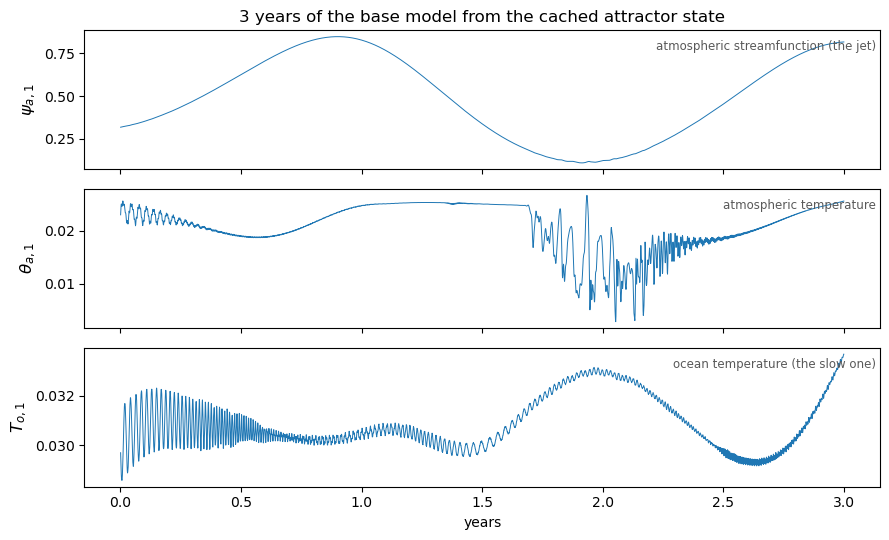

In [5]:
x_attr = get_attractor_ic(tw, cfg)

WRITE_EVERY = 30                                   # 0.34 d per sample: resolves weather
n_steps = config.days_to_steps(365 * 3)
traj = np.asarray(jm.integrate(tw.T_base, x_attr, config.DT, n_steps, write_every=WRITE_EVERY))
years = config.steps_to_days(np.arange(1, len(traj) + 1) * WRITE_EVERY) / 365.0

MODES = [(tw.idx_psia1,   r"$\psi_{a,1}$", "atmospheric streamfunction (the jet)"),
         (tw.idx_thetaa1, r"$\theta_{a,1}$", "atmospheric temperature"),
         (tw.idx_To1,     r"$T_{o,1}$", "ocean temperature (the slow one)")]

fig, axes = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True)
for ax, (k, sym, desc) in zip(axes, MODES):
    ax.plot(years, traj[:, k], lw=0.7)
    ax.set_ylabel(sym, fontsize=12)
    ax.text(0.995, 0.93, desc, transform=ax.transAxes, ha="right", va="top",
            fontsize=8.5, color="0.35")
axes[-1].set_xlabel("years")
axes[0].set_title("3 years of the base model from the cached attractor state")
fig.tight_layout(); plt.show()

The same trajectory as a shape rather than three time series. Projected onto the fast mode
against the slow one, the trajectory is not a tangle — it is a broad, slowly-traversed loop
with weather riding on it, which is what "weakly chaotic" looks like here.

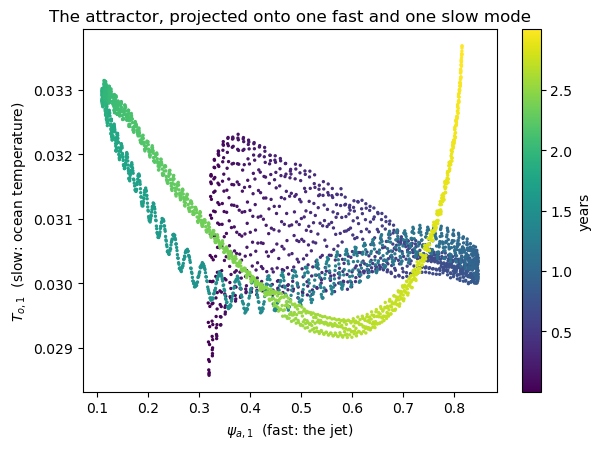

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 4.6))
sc = ax.scatter(traj[:, tw.idx_psia1], traj[:, tw.idx_To1],
                c=years, s=2, cmap="viridis")
ax.set_xlabel(r"$\psi_{a,1}$  (fast: the jet)")
ax.set_ylabel(r"$T_{o,1}$  (slow: ocean temperature)")
ax.set_title("The attractor, projected onto one fast and one slow mode")
fig.colorbar(sc, ax=ax, label="years")
fig.tight_layout(); plt.show()

## 2. The injected error

The "truth" model is the base model plus a known, state-dependent error in the
atmosphere–ocean thermal exchange:

```
f_true(x) = f_base(x) + eps * g(x) * (E @ x)
g(x)      = a0 + a1*theta_a1 + a2*T_o1 + a3*psi_a1
```

`E` is a constant operator, so the error is linear in the coefficients. The discovery model
has the same shape with a *learnable* `c`, which puts the truth exactly inside the model class
at `c_true = eps * g_coeffs`. The project default is `eps = 0.1` with `g(x) = T_o1` — one
nonzero entry.

In [7]:
print("c_true      =", np.asarray(tw.c_true), "   (= eps * g_coeffs)")
print("features(x) =  (1, theta_a1, T_o1, psi_a1)  ->",
      np.round(np.asarray(tw.features(jnp.asarray(traj[0]))), 5))

m_err = formfit.err_tendency(tw, traj)                      # m(x) = f_true(x) - f_base(x)
f_base = np.asarray(jax.vmap(lambda x: tw.f_base(x))(jnp.asarray(traj)))
print(f"\n||m|| / ||f_base||  =  {np.linalg.norm(m_err)/np.linalg.norm(f_base):.3e}")
print("  -> the error is ~5e-5 of the base tendency. It is climatologically SILENT:")
print("     it does not show up in the statistics you would normally check, which is")
print("     exactly what makes being able to discover it worth anything (--climatology).")

c_true      = [0.  0.  0.1 0. ]    (= eps * g_coeffs)
features(x) =  (1, theta_a1, T_o1, psi_a1)  -> [1.      0.023   0.02969 0.31767]



||m|| / ||f_base||  =  3.577e-05
  -> the error is ~5e-5 of the base tendency. It is climatologically SILENT:
     it does not show up in the statistics you would normally check, which is
     exactly what makes being able to discover it worth anything (--climatology).


### `E` only touches the thermal coupling

The exchange operator is where the error lives, and it is far from full: it acts on the
`theta_a` and `T_o` rows and nowhere else. Left, its sparsity pattern with the four state
blocks marked; right, the error tendency along the trajectory above.

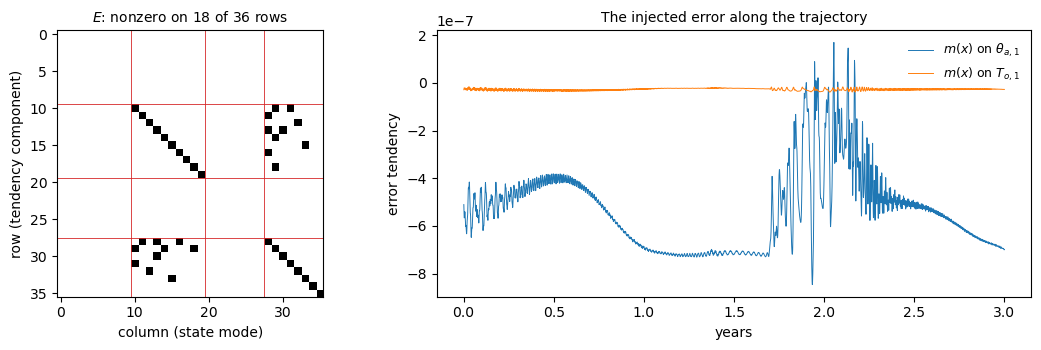

E acts on rows 10..35 — the theta_a and T_o blocks


In [8]:
E = np.asarray(tw.E_full)
rows = np.where(np.abs(E).sum(1) > 0)[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6),
                               gridspec_kw={"width_ratios": [1, 1.5]})

ax1.imshow(np.abs(E) > 0, cmap="Greys", interpolation="nearest")
for b in vr[:-1]:
    ax1.axhline(b - 0.5, color="tab:red", lw=0.6)
    ax1.axvline(b - 0.5, color="tab:red", lw=0.6)
ax1.set_title(f"$E$: nonzero on {len(rows)} of {tw.ndim} rows", fontsize=10)
ax1.set_xlabel("column (state mode)"); ax1.set_ylabel("row (tendency component)")

ax2.plot(years, m_err[:, tw.idx_thetaa1], lw=0.7, label=r"$m(x)$ on $\theta_{a,1}$")
ax2.plot(years, m_err[:, tw.idx_To1], lw=0.7, label=r"$m(x)$ on $T_{o,1}$")
ax2.set_xlabel("years"); ax2.set_ylabel("error tendency")
ax2.set_title("The injected error along the trajectory", fontsize=10)
ax2.legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

print(f"E acts on rows {rows.min()}..{rows.max()} — the theta_a and T_o blocks")

## 3. Recovering it, once

Assume for a moment the *form* is known and only the four coefficients are unknown. Because
the model class contains the truth, this is a nonlinear least-squares problem with a known
global minimum and zero residual in the noiseless limit. `discovery.recover` rolls the
discovery model through RK4, scores it against the truth trajectory, and fits `c` by
Levenberg–Marquardt on the autodiff residual Jacobian.

One window, to show the machinery works:

In [9]:
W = 1280                                       # steps; ~14 days
mask = obs_mask(tw.ndim, vr, "full")           # observe all 36; try "atmos" / "ocean" / "temp"
Y_true = np.asarray(discovery.rollout(lambda y: tw.f_true(y), x_attr, config.DT, W))

r = discovery.recover(tw, x_attr, Y_true, config.DT, mask, eta=0.0, n_iters=cfg.lm_iters)
print(f"window     {W} steps = {config.steps_to_days(W):.2f} days")
print(f"c_true     {np.asarray(tw.c_true)}")
print(f"c_hat      {np.round(r['c_hat'], 12)}")
print(f"rel_err    {r['rel_err']:.2e}")
print(f"cond(JtJ)  {r['cond']:.2e}   (conditioning of the parameter -> observation map)")

window     1280 steps = 14.36 days
c_true     [0.  0.  0.1 0. ]
c_hat      [-1.e-12  4.e-12  1.e-01  3.e-12]
rel_err    6.32e-11
cond(JtJ)  1.76e+07   (conditioning of the parameter -> observation map)


That is the easy half of the problem, at one favourable window. The two questions the project
actually turns on are elsewhere:

- **How does this degrade?** `cond(JtJ)` explodes to ~1e15 at half a day and the recovery
  falls to 1e-3, while observation noise closes the window from the other end. That sweep is
  the default study — `python -m error_discovery.run_all`.
- **What if the form is *not* known?** Then the fit has to choose among candidate forms, and
  on the model's own attractor it cannot: a near-constant mode aliases every candidate. That
  is the project's headline and it lives in `--form`, `--obstruction` and `--why`.

## 4. Driving the studies from the command line

One study runs per invocation:

```bash
python -m error_discovery.run_all --help       # every study, one line each
python -m error_discovery.run_all              # the default lead-time study
python -m error_discovery.run_all --form       # form discovery from trajectories
```

A study's knobs are just its own keyword arguments. `--list-params` lists them and
`--set key=value` reaches them — both read `inspect.signature` over the functions the study
actually calls, so there is no second list to keep in sync. **Exposing a knob means giving it
a keyword argument, and nothing else.**

In [10]:
def cli(*args):
    r = subprocess.run([sys.executable, "-m", "error_discovery.run_all", *args],
                       capture_output=True, text=True)
    print(r.stdout or r.stderr)

cli("--param-tuning", "--list-params")

--param-tuning: parameters, set with --set key=value

  window    = 40                             [run]
  n_windows = 6                              [run]
  spinup    = 40000                          [run]
  gap       = 2000                           [run]
  n_iters   = 300                            [run]
  lr        = 0.05                           [run]
  beta1     = 0.9                            [run]
  beta2     = 0.999                          [run]
  seed      = 2024                           [run]
  verbose   = True                           [run]



Studies come in two shapes, and `--list-params` reads both off the same signatures. The one
above takes plain keyword arguments. The default lead-time study instead takes an
`ExperimentConfig`, so its parameters are that dataclass's fields — the `[config]` tag below
marks them.

In [11]:
cli("--list-params")

--leadtime: parameters, set with --set key=value

  eps              = 0.1                            [config]
  g_coeffs         = (0.0, 0.0, 1.0, 0.0)           [config]
  dt               = 0.1                            [config]
  spinup_steps     = 800000                         [config]
  n_ic             = 4                              [config]
  ic_spacing_steps = 3000                           [config]
  window_steps     = (40, 80, 160, 320, 480, 640, 960, 1280, 1920, 2560, 3840, 5120, 8000) [config]
  obs              = 'full'                         [config]
  noise_levels     = (0.0001, 0.0003, 0.001)        [config]
  noise_windows    = (320, 640, 1280, 2560, 5120)   [config]
  n_noise_seeds    = 3                              [config]
  lm_iters         = 40                             [config]
  lyap_blocks      = 200                            [config]
  seed             = 21217                          [config]
  tag              = 'main'                         [conf

Values are parsed against the **type of the default**, which is what makes `--set
whiten=false` mean false rather than the truthy string `"false"`, and `--set
windows=(320,640)` give a tuple.

```bash
python -m error_discovery.run_all --driver-scan --set n=8000 --set reps=40
python -m error_discovery.run_all --set whiten=true --set tag=main_whiten   # manuscript Fig. 2
python -m error_discovery.run_all --param-tuning --set lr=0.01 --set n_iters=800
```

### `run()` and `figure()` are separate, on purpose

Every study module answers to the same pair:

```python
run(...)      # computes, writes .npz to RESULTS_DIR, returns its results
figure(...)   # reloads that .npz, draws, returns the list of paths written
```

`run` never draws and `figure` never computes, so a figure redraws from cached results in
about a second without repeating the expensive part. Re-rendering all 18 drawing studies
takes ~3 s, and it is the only check that covers the drawing code and the `STUDIES` table —
no test calls any `run()` or `figure()`:

```python
from error_discovery.experiments import form
form.figure()                     # -> results/fig_form_*.png, from cached form_results.npz
```

### One trap before you use `--quick`

`--quick` swaps in `config.QUICK`, a smoke-test preset — and `QUICK.spinup_steps` is 50,000
against the default 800,000. `get_attractor_ic` checks the recipe, sees a mismatch, and
**rebuilds and overwrites the shared IC cache**. The next study you run rebuilds it again, at
about two minutes each time. To shrink a run without touching the cache, override the other
fields with `--set` and leave `spinup_steps` alone.

### What it all produces

Committed figures under `results/`, displayed here from disk rather than regenerated. Two of
the eighteen:

fig_alias.png


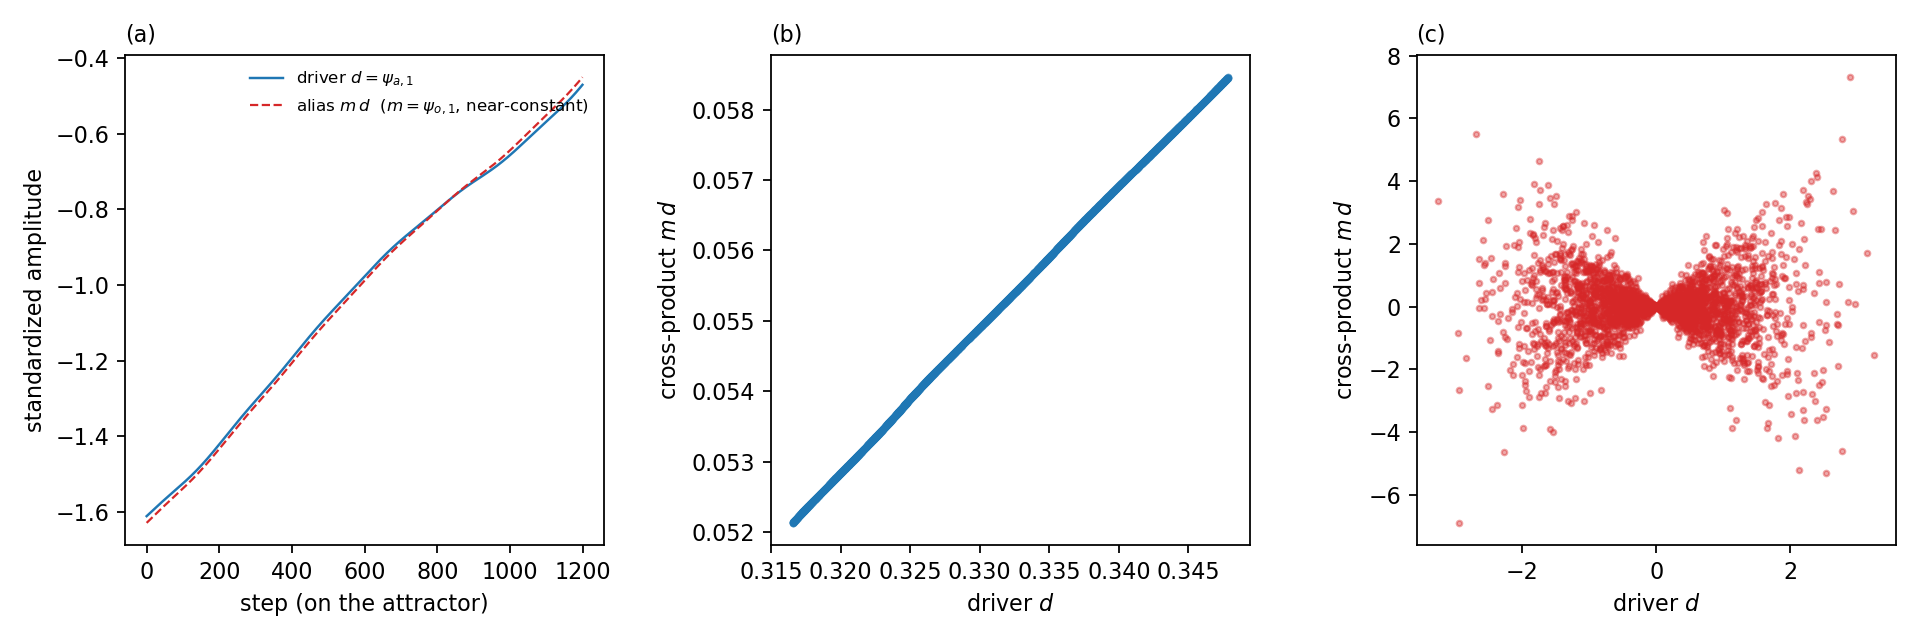

fig_param_tuning.png


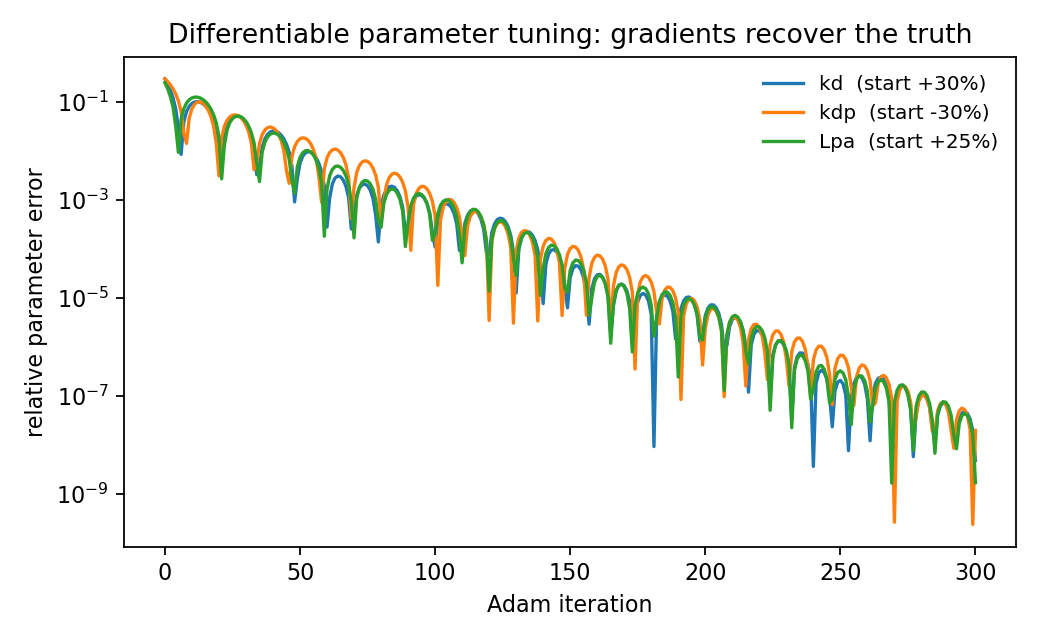

In [12]:
for name in ("fig_alias.png", "fig_param_tuning.png"):
    path = os.path.join(config.RESULTS_DIR, name)
    print(name)
    display(Image(path))

Left to right in `fig_alias`: on the model's own attractor a near-constant mode times a
candidate driver is indistinguishable from the driver itself, so the error's *form* cannot be
identified — the mechanism behind `--obstruction`, `--reanalysis` and `--increment`. Under
broad excitation the alias breaks, which is why off-attractor data works (`--overcomplete`).

`fig_param_tuning` is the warm-up (`--param-tuning`): with the right structure and wrong
constants, Adam through the integrator walks three physical parameters back to truth. Nothing
about a genuinely missing term is that obliging, which is the contrast the rest of the package
is built on.

**Where to go next:** `error_discovery/README.md` for the index of what exists, and each
study's module docstring for the question it asks and what it found.